# Enhancer code part 2: designing synthetic enhancers

## Overview

In part 1 we used a deep learning model as a **reading** device: we asked which nucleotides it uses and which TF motifs make an enhancer specific to a brain cell type. In this notebook we turn the model around and use it as a **writing** device. We will build DNA sequences that do not exist in any genome, but that the model predicts to be strong, cell-type-specific enhancers.

Why would anyone want to do that? There are two answers, and both matter.

**Because it is the hardest test of whether we understood the code.** Part 1 ended with a vocabulary: these motifs belong to those cell types. That is a claim about correlation, and a model could produce it while having memorised which regions are accessible where. Writing is different. If we take DNA that has never existed, insert the words we think we have learned, and the model says "this is a microglial enhancer", then the vocabulary carries real information about sequence rather than about the particular regions we trained on. Reading can be fooled by memorisation; writing cannot be, at least not in the same way.

**Because a cell-type-specific enhancer is a tool for reaching one cell type and nothing else.** Suppose you want to correct a gene in microglia, or silence a neuron type to find out what it does, or light up astrocytes to watch them. You can deliver DNA to the brain with a virus, but a virus does not know which cell it lands in. What decides where the cargo switches on is the enhancer you put in front of it. An enhancer active only in microglia turns an untargeted delivery into a targeted treatment — the gene is carried everywhere and expressed in one place.

That is the practical reason this field exists. Natural enhancers are often not specific enough, or are too long to fit in a virus, and you cannot order one that does exactly what you want. Designing one, in a computer, from a model of the code, means you can — and the designs can then be synthesised and tested. This is not hypothetical: enhancers designed this way have been tested in mice and in human brain organoids.

The honest caveat up front: everything we produce here is a **hypothesis generated by a model**, scored by the same model. The point of designing in a computer is to narrow millions of possibilities to a handful worth making in a lab.

**The workflow of this notebook:**
1. **Set up** and see what the model thinks of random DNA.
2. **Understand the design procedure** with a slow version written out by hand.
3. **Evolve** enhancers from random DNA for three cell types, and watch the binding sites appear one mutation at a time.
4. **Convert** one natural enhancer into three different cell types.
5. **Build with the motifs of part 1** and steer random sequences towards a chosen cell type.

Throughout we design for **three** cell types, one from each group of part 1: `Micro_PVM` (non-neuronal), `L2_3IT` (excitatory) and `Pvalb` (inhibitory). A method that only worked for microglia, whose motifs are the most distinctive in the atlas, would tell us much less than one that works across the three.

Step 5 is the direct test of part 1: the motifs we insert there are the ones we discovered ourselves by explaining the model.

**Before you start:** run part 1 first, this notebook uses the files it saved in `results/`. The environment is the same, so nothing new to install.

## Biological question

In part 1 we found which TF motifs the model associates with each cortex cell type. That was a **correlation**: these motifs are enriched in regions the model scores highly.

Here we ask a causal-style question, at least as far as the model is concerned:

**If we add those motifs to a piece of DNA, does it become a cell-type-specific enhancer?**

**Research questions**

1. Can a model turn random DNA into a sequence it recognises as a strong microglia enhancer, and what does it write into it?
2. How much has to change to convert an enhancer of one cell type into another?
3. Is adding the "right" motifs enough, or do their number and context matter too?
4. What do these designs *not* tell us, and what experiment would settle it?

## Part 1: Setting up

### Selecting the kernel and installing the Python environment

This practical uses its own **Conda/Mamba environment**, `regulatory_genomics_enhancers`. It is separate from the `regulatory_genomics` environment of the single-nucleus and spatial practicals because the deep learning libraries (TensorFlow, CREsted, TF-MINDI) need their own, specific package versions. You only need to create it **once**, and the same environment is used for part 1 and part 2.

Run the following in a **terminal on the computer/VSC cluster where you use Jupyter**, not in a notebook code cell:

```bash
mamba create -n regulatory_genomics_enhancers -c conda-forge python=3.12 pip ipykernel ipywidgets numpy pandas matplotlib seaborn "scanpy>=1.12.5" anndata
conda activate regulatory_genomics_enhancers
pip install tensorflow "crested[motif]" "tfmindi>=2"
```

- **TensorFlow** is the deep learning library that runs the neural network.
- **CREsted** loads trained enhancer models, makes predictions, explains them and designs new sequences.
- **TF-MINDI** groups the important pieces of DNA found by the model into transcription factor motifs, and annotates each motif with the transcription factor family that binds it. Version 2 or newer is required.

The `scanpy>=1.12.5` is not optional: older versions crash when clustering more than a few thousand seqlets with recent SciPy.

The installation may take 10–15 minutes. Then **register a Jupyter kernel**:

```bash
conda activate regulatory_genomics_enhancers
python -m ipykernel install --user --name regulatory_genomics_enhancers --display-name "Python (regulatory_genomics_enhancers)"
jupyter kernelspec list
```

Open the notebook in VS Code or Jupyter and choose **Python (regulatory_genomics_enhancers)** via **Select Kernel** (VS Code) or **Kernel → Change Kernel** (Jupyter).

Everything in this practical runs on a normal laptop CPU; a GPU is not needed (though it will speed things up). The slowest steps take 10–20 minutes and are marked in the text.

### Step 0: Load the model and the results of part 1

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CRESTED_DATA_DIR"] = "data/crested"
os.environ["TFMINDI_DATA_DIR"] = "data/tfmindi"

from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import crested
import tfmindi as tm

DATA = Path("data")
RESULTS = Path("results")

genome = crested.Genome(DATA / "genome/mm10.fa", DATA / "genome/mm10.chrom.sizes")
crested.register_genome(genome)

model_file, cell_types = crested.get_model("DeepBICCN2")
model = crested.utils.load_model(model_file)

# one target cell type from each of the three groups
TARGETS = {"non-neuronal": "Micro_PVM", "excitatory": "L2_3IT", "inhibitory": "Pvalb"}
TARGET = TARGETS["non-neuronal"]          # the one we follow step by step
TARGET_IDX = cell_types.index(TARGET)
WIDTH = model.input_shape[1]

print("cell types:", len(cell_types), "| designing for:", list(TARGETS.values()),
      "| sequence length:", WIDTH)

2026-11-05T02:24:49.942554+0100 INFO Genome mm10 registered.


cell types: 19 | designing for: ['Micro_PVM', 'L2_3IT', 'Pvalb'] | sequence length: 2114


### Step 0b: A reference set of real enhancers

Throughout this notebook we will compare our designs with two things: random DNA, and **real** enhancers of the cell type we design for. For the second we need predictions on a set of genuine candidate regions, so we score a sample of the atlas's consensus peaks here.

Each peak is 500 bp and the model wants 2,114 bp, so every peak is extended around its centre. Half a million regions would take hours, so we take a random sample of 5,000: enough to find strongly specific enhancers and to see how rare they are.

**This step takes about ten minutes** and the result is cached.

In [2]:
peaks_file = DATA / "biccn" / "consensus_peaks_biccn.bed"
if not peaks_file.exists():
    peaks_file.parent.mkdir(exist_ok=True)
    urlretrieve("https://resources.aertslab.org/CREsted/data/mouse_biccn/consensus_peaks_biccn.bed",
                peaks_file)

peaks = pd.read_csv(peaks_file, sep="	", header=None, names=["chrom", "start", "end", "name"])
peaks = peaks[peaks["chrom"].str.match(r"^chr[0-9XY]+$")]
centre = (peaks["start"] + peaks["end"]) // 2
regions = (peaks["chrom"] + ":" + (centre - WIDTH // 2).astype(str)
           + "-" + (centre + WIDTH - WIDTH // 2).astype(str)).tolist()
print(f"{len(regions):,} candidate enhancers")

546,993 candidate enhancers


In [3]:
prediction_file = RESULTS / "biccn_predictions.csv"
if prediction_file.exists():
    predictions = pd.read_csv(prediction_file, index_col=0)
else:
    rng_sample = np.random.default_rng(0)
    sample = [regions[i] for i in rng_sample.choice(len(regions), 5000, replace=False)]
    predictions = pd.DataFrame(crested.tl.predict(sample, model, verbose=0),
                               index=sample, columns=cell_types)
    values = predictions[cell_types].to_numpy()
    ranked = np.sort(values, axis=1)
    predictions["specificity"] = ranked[:, -1] - ranked[:, -2]
    predictions["best_cell_type"] = predictions[cell_types].idxmax(axis=1)
    predictions.to_csv(prediction_file)

print(predictions.shape)
predictions.nlargest(5, "specificity")[["best_cell_type", "specificity"]].round(1)

(5000, 21)


,best_cell_type,specificity
chr5:114578886-114581000,Oligo,59.8
chr10:83905795-83907909,Oligo,45.8
chr11:104970522-104972636,Oligo,44.1
chrX:96129817-96131931,Micro_PVM,39.9
chr1:156436493-156438607,Micro_PVM,34.7


**Specificity** here is the highest prediction minus the second highest: large when a region is accessible in one cell type and quiet in the rest, near zero when it is open everywhere. The most specific regions are the real enhancers we will hold our designs up against.

We keep the **same colours for the same cell types** as in part 1, so that a figure here can be compared with a figure there without re-reading the legend.

In [4]:
# One colour per cell type, used in every figure of both notebooks.
# The order is the one we use everywhere: non-neuronal, then excitatory, then inhibitory.
CELL_TYPE_COLOURS = {
    # non-neuronal
    "Astro":     "#009E73",
    "Oligo":     "#0072B2",
    "OPC":       "#543005",
    "Micro_PVM": "#D55E00",
    "Endo":      "#332288",
    "VLMC":      "#66A61E",
    # excitatory neurons
    "L2_3IT":    "#CC79A7",
    "L5IT":      "#003C30",
    "L6IT":      "#DDCC77",
    "L5ET":      "#B2182B",
    "L5_6NP":    "#E7298A",
    "L6CT":      "#C49C94",
    "L6b":       "#EE8866",
    # inhibitory interneurons
    "Pvalb":     "#E69F00",
    "Sst":       "#882255",
    "SstChodl":  "#A6761D",
    "Vip":       "#56B4E9",
    "Lamp5":     "#BBCC33",
    "Sncg":      "#8C564B",
}
GREY = "#CCCCCC"  # anything without a colour of its own

CELL_TYPES = list(CELL_TYPE_COLOURS)          # all 19, in the order above
CELL_TYPE_GROUPS = {"non-neuronal": CELL_TYPES[:6],
                    "excitatory": CELL_TYPES[6:13],
                    "inhibitory": CELL_TYPES[13:]}

def cell_colour(cell_type):
    """The agreed colour of a cell type."""
    return CELL_TYPE_COLOURS.get(cell_type, GREY)

In [5]:
# the model lists its classes alphabetically; every plot below uses the grouped order instead
assert set(cell_types) == set(CELL_TYPES), "model classes differ from the palette"
print("plot order:", ", ".join(CELL_TYPES))

plot order: Astro, Oligo, OPC, Micro_PVM, Endo, VLMC, L2_3IT, L5IT, L6IT, L5ET, L5_6NP, L6CT, L6b, Pvalb, Sst, SstChodl, Vip, Lamp5, Sncg


In [6]:
from matplotlib.ticker import MultipleLocator

def motif_span(scores, one_hot, class_index=0, sequence_index=0,
               pad=30, min_span=200, max_span=320):
    """The stretch of the sequence that actually carries contribution.

    Returns (start, end) positions in the sequence, so we can zoom a plot onto the
    motifs instead of showing 2,114 bp of mostly-empty track. If the important
    positions are spread over more than `max_span`, we keep the `max_span` window
    that carries the most contribution: a window wide enough to hold every motif is
    usually too wide to read the letters in.
    """
    length = scores.shape[2]
    track = np.abs((scores[sequence_index, class_index] * one_hot[sequence_index]).sum(axis=1))
    important = np.where(track > 0.1 * track.max())[0]
    start, end = int(important.min()) - pad, int(important.max()) + pad
    if end - start > max_span:
        densest = int(np.argmax(np.convolve(track, np.ones(max_span), mode="valid")))
        start, end = densest, densest + max_span
    if end - start < min_span:                      # never zoom in further than min_span
        centre = (start + end) // 2
        start, end = centre - min_span // 2, centre + min_span // 2
    return max(0, start), min(length, end)

def plot_contributions(scores, one_hot, labels, class_labels, span=None, **kwargs):
    """Draw contribution logos.

    `span` is a (start, end) pair in sequence coordinates; without it the whole
    sequence is drawn. The x axis always shows the real position in the sequence,
    so a zoomed plot starts at the position it zoomed to rather than at 0.
    """
    length = scores.shape[2]
    start, end = span if span is not None else (0, length)
    zoom = end - start
    x_shift = start - length // 2 + zoom // 2
    fig, axes = crested.pl.explain.contribution_scores(
        scores, one_hot,
        sequence_labels=labels, class_labels=class_labels,
        zoom_n_bases=zoom, x_shift=x_shift,
        coordinates=(0, length),   # label the x axis with positions in the sequence
        show=False, **kwargs,
    )
    tick = max(10, int(round(zoom / 8 / 10)) * 10)   # aim for about eight ticks
    for ax in np.atleast_1d(axes):
        ax.xaxis.set_major_locator(MultipleLocator(tick))
    plt.show()

### The DeepBICCN2 model: where it comes from and what it predicts

We do not train a model in this practical (training is covered in a separate session). Instead we use **DeepBICCN2**, a model published with CREsted and distributed with it.

Watch the digit. CREsted also ships a model called **DeepBICCN**, and the two are easy to confuse. They have the same architecture and the same 6.3 million parameters, and were trained on the same atlas — but on two different ways of summarising the same ATAC-seq data. `DeepBICCN` predicts the **mean coverage** over the middle of a peak; `DeepBICCN2` predicts **Tn5 cut-site counts**, the positions where the enzyme actually cut. We use `DeepBICCN2` here, and the precomputed contribution scores of part 1 were made with it too.

**What goes in.** A DNA sequence of exactly 2,114 base pairs.

**What comes out.** 19 numbers, one per cortex cell type:

| Group | Cell types |
|---|---|
| Non-neuronal | `Astro` (astrocytes), `Oligo` (oligodendrocytes), `OPC`, `Micro_PVM` (microglia), `Endo`, `VLMC` |
| Excitatory neurons | `L2_3IT`, `L5IT`, `L6IT`, `L5ET`, `L5_6NP`, `L6CT`, `L6b` |
| Inhibitory neurons | `Pvalb`, `Sst`, `SstChodl`, `Vip`, `Lamp5`, `Sncg` |

Each number is the **accessibility the model expects in that cell type**: how many Tn5 cut sites (the ATAC-seq signal) it predicts over the central 1,000 bp of the sequence. Unlike a probability these values are not capped at 1; a strong, specific enhancer can score 30 or more in its own cell type and near zero everywhere else.

**How it was trained (in short).** Training means showing the model many sequences together with the right answer and adjusting its 6.3 million internal parameters until its predictions match. DeepBICCN2 was trained in two stages:

1. First on **all** consensus peaks of a single-cell ATAC-seq atlas of the mouse primary motor cortex, learning the general relationship between sequence and accessibility.
2. Then **fine-tuned** on the subset of regions that are specific to one cell type, which sharpens exactly the distinction we care about here.

Crucially, the model only ever saw **DNA sequence**: no gene names, no positions in the genome, no information about which TFs exist. If it predicts cell-type-specific accessibility correctly, it must have learned which sequence features (TF binding sites) make a region accessible in a microglium and not in a neuron. Reading that knowledge back out is what this practical is about.

> Kempynck N, De Winter S, et al. *CREsted: modeling genomic and synthetic cell-type-specific enhancers across tissues and species.* Nature Methods (2026). The data come from Zemke NR, Armand EJ, Wang W, et al. *Conserved and divergent gene regulatory programs of the mammalian neocortex.* Nature (2023) 624:390–402, which profiled the primary motor cortex.

### Step 1: What does random DNA look like to the model?

Before designing anything we need a **baseline**. If a designed sequence later scores 20 for microglia, is that impressive? Only if random DNA scores much lower.

We generate random sequences of 2,114 bp. To make them a fair baseline we do not use 25% of each nucleotide but the composition of real accessible regions.

In [7]:
acgt_distribution = crested.utils.calculate_nucleotide_distribution(
    predictions.sample(1000, random_state=0).index.tolist()
)
print("A, C, G, T frequencies in accessible regions:", acgt_distribution.round(3))

rng = np.random.default_rng(0)
random_sequences = ["".join(rng.choice(list("ACGT"), WIDTH, p=acgt_distribution)) for _ in range(100)]
random_predictions = pd.DataFrame(
    crested.tl.predict(random_sequences, model, verbose=0), columns=cell_types)
print(random_predictions.shape, "-> (random sequences, cell types)")

A, C, G, T frequencies in accessible regions: [0.271 0.23  0.23  0.269]


(100, 19) -> (random sequences, cell types)


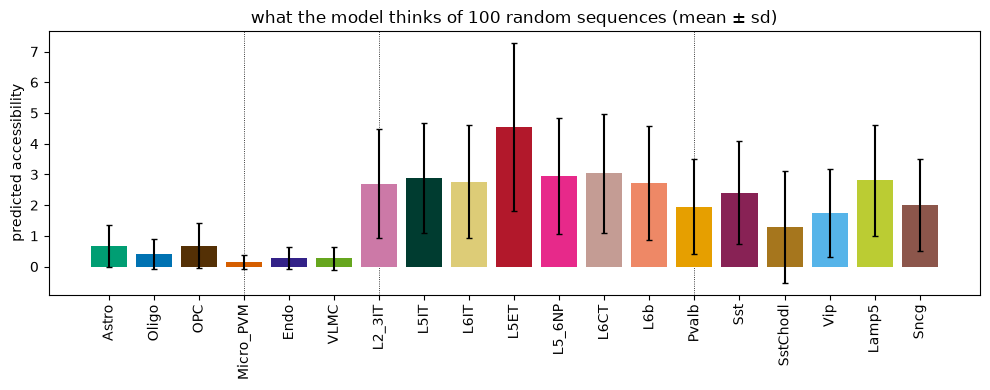

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(CELL_TYPES, random_predictions[CELL_TYPES].mean(),
       yerr=random_predictions[CELL_TYPES].std(),
       color=[cell_colour(c) for c in CELL_TYPES], capsize=2)
for name in TARGETS.values():
    ax.axvline(CELL_TYPES.index(name), color="black", lw=0.6, ls=":", zorder=0)
ax.set_ylabel("predicted accessibility")
ax.set_title("what the model thinks of 100 random sequences (mean ± sd)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
baseline = pd.DataFrame({
    "random DNA (best of 100)": [random_predictions[t].max() for t in TARGETS.values()],
    "real enhancers (best)": [predictions[t].max() for t in TARGETS.values()],
}, index=list(TARGETS.values())).round(1)
baseline["ratio"] = (baseline.iloc[:, 1] / baseline.iloc[:, 0]).round(0)
baseline

,random DNA (best of 100),real enhancers (best),ratio
Micro_PVM,1.6,50.2,31.0
L2_3IT,9.0,67.9,8.0
Pvalb,7.5,30.5,4.0


Random DNA scores far below real microglia enhancers. The model has clearly learned that a cell-type-specific enhancer needs specific sequence features, which random DNA almost never contains by chance.

**Question**: Why use the nucleotide composition of accessible regions rather than 25% of each base? What could you wrongly conclude if your random sequences were much more AT-rich than real enhancers?

## Part 2: How enhancer design works

### Step 2: One step of evolution, by hand

The method is called **in silico evolution**: evolution inside the computer. It mimics natural selection, but "survival" is decided by the model rather than by an organism. One round works like this:

1. Take the current sequence.
2. Make **every possible single-nucleotide mutation** in the part we allow to change.
3. Ask the model to score all of them.
4. Keep the mutation that improves the score the most.

Repeat, and the sequence slowly "evolves" towards whatever the model likes.

One practical point. Our sequences are 2,114 bp, so trying every mutation everywhere would mean 6,342 predictions per round and hours of computing. The model predicts accessibility over the **central 1,000 bp**, so mutations far out in the flanks matter least. We therefore only mutate a window in the middle, which is what `target_len` controls.

The function below does one round by hand on a 200 bp window, so you can see what happens.

In [10]:
TARGET_LEN = 200   # only mutate this many bp in the centre

def one_round_of_evolution(sequence, target_idx, model, target_len=TARGET_LEN):
    """Try all single-nucleotide mutations in the central window and return the best one."""
    start = (len(sequence) - target_len) // 2
    variants, changes = [], []
    for position in range(start, start + target_len):
        for nucleotide in "ACGT":
            if nucleotide != sequence[position]:
                variants.append(sequence[:position] + nucleotide + sequence[position + 1:])
                changes.append((position, nucleotide))
    scores = crested.tl.predict(variants, model, verbose=0)[:, target_idx]
    best = int(np.argmax(scores))
    return variants[best], changes[best], scores[best]

start_sequence = random_sequences[0]
start_score = crested.tl.predict(start_sequence, model, verbose=0)[0, TARGET_IDX]
new_sequence, (position, nucleotide), new_score = one_round_of_evolution(
    start_sequence, TARGET_IDX, model)

print(f"start {TARGET} score: {start_score:.2f}")
print(f"best mutation: position {position}, {start_sequence[position]} -> {nucleotide}")
print(f"new {TARGET} score:   {new_score:.2f}")

start Micro_PVM score: 0.03
best mutation: position 1036, C -> G
new Micro_PVM score:   0.05


A single nucleotide already lifts the score. One mutation cannot create a whole binding site, but it can complete a sequence that was already close to one.

**Question**: This procedure always takes the single best mutation (a "greedy" search). Can you think of a case where a sequence would need two mutations at once to improve, and what this strategy would do then?

### Step 3: Keeping the design specific

There is a catch. If we only maximise the microglia score, we might end up with a sequence that is accessible in *every* cell type. That is not what we want: a useful designed enhancer is **specific**.

CREsted's default optimisation therefore does not maximise the target alone, but a difference: it rewards an increase in the target cell type and penalises increases in the others. At every step it asks "which mutation makes this sequence *more microglial than anything else*?"

This is the same idea as the specificity score of part 1, now used as a steering wheel instead of a ranking.

## Part 3: Designing enhancers for three kinds of cell

### Step 4: Evolve from scratch

We now run the loop properly, for **three target cell types**, one from each of the three groups of part 1: `Micro_PVM` (non-neuronal), `L2_3IT` (excitatory) and `Pvalb` (inhibitory). Doing all three rather than one is the point — if the method only worked for microglia, whose motifs are the most distinctive of the whole atlas, we would have learned much less.

For each target we start from two random sequences and allow 20 mutations, recording every step. **This takes about an hour and a half**; the result is cached, so it only runs once.

Two starting sequences per target is also deliberate. You will see why in a moment.

In [11]:
design_file = RESULTS / "designed_evolution.npz"

def cached(path, keys):
    """The cached arrays, or None if the cache was made for different targets."""
    if not path.exists():
        return None
    saved = np.load(path, allow_pickle=True)
    return saved if all(k in saved.files for k in keys) else None

saved = cached(design_file, [f"{k}_{s}" for k in TARGETS.values() for s in ("seq", "steps")])
if saved is not None:
    evolution = {k: {"sequences": list(saved[f"{k}_seq"]), "steps": list(saved[f"{k}_steps"])}
                 for k in TARGETS.values()}
else:
    evolution = {}
    for name in TARGETS.values():
        print(f"evolving {name} ...")
        np.random.seed(0)
        steps, seqs = crested.tl.design.in_silico_evolution(
            n_mutations=20,
            target=cell_types.index(name),
            model=model,
            n_sequences=2,
            target_len=TARGET_LEN,
            acgt_distribution=acgt_distribution,
            return_intermediate=True,
        )
        evolution[name] = {"sequences": list(seqs), "steps": list(steps)}
    np.savez(design_file, **{f"{k}_seq": np.array(v["sequences"], dtype=object)
                             for k, v in evolution.items()},
             **{f"{k}_steps": np.array(v["steps"], dtype=object)
                for k, v in evolution.items()})

for name, run in evolution.items():
    print(f"{name}: {len(run['sequences'])} sequences of {len(run['sequences'][0])} bp")

Micro_PVM: 2 sequences of 2114 bp
L2_3IT: 2 sequences of 2114 bp
Pvalb: 2 sequences of 2114 bp


### Step 5: Follow the design process

The recorded steps let us plot how the predictions changed with every mutation. This plot is the heart of the method: it shows the model being steered — or failing to be. Each row is a target cell type, each column one of its two starting sequences. The coloured line is the target; the grey lines are the other 18 cell types.

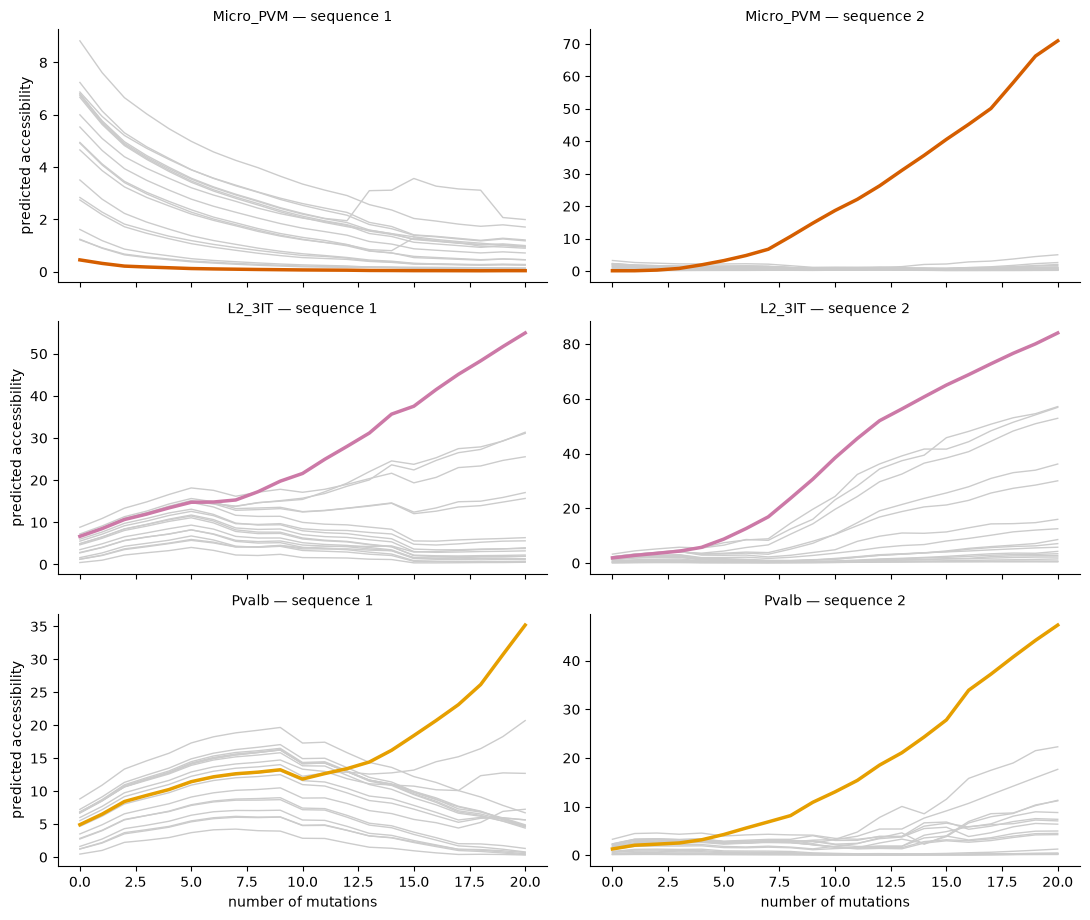

In [12]:
fig, axes = plt.subplots(len(TARGETS), 2, figsize=(11, 3.1 * len(TARGETS)), sharex=True)
for row, name in enumerate(TARGETS.values()):
    for col, record in enumerate(evolution[name]["steps"]):
        ax = axes[row, col]
        steps = pd.DataFrame(record["predictions"], columns=cell_types)
        for cell_type in cell_types:
            on_target = cell_type == name
            ax.plot(steps.index, steps[cell_type],
                    color=cell_colour(name) if on_target else GREY,
                    lw=2.5 if on_target else 1, zorder=3 if on_target else 1)
        ax.set_title(f"{name} — sequence {col + 1}", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
    axes[row, 0].set_ylabel("predicted accessibility")
for ax in axes[-1]:
    ax.set_xlabel("number of mutations")
plt.tight_layout()
plt.show()

In [13]:
summary = pd.DataFrame(
    {name: [np.asarray(r["predictions"])[-1, cell_types.index(name)]
            for r in evolution[name]["steps"]] for name in TARGETS.values()},
    index=["sequence 1", "sequence 2"],
).T
summary["best real enhancer"] = [predictions[name].max() for name in TARGETS.values()]
summary.round(1)

,sequence 1,sequence 2,best real enhancer
Micro_PVM,0.000000,70.900002,50.2
L2_3IT,54.900002,84.000000,67.9
Pvalb,35.200001,47.299999,30.5


Six runs, and they do not all tell the same story. That is the value of doing three cell types instead of one.

**Five of the six worked, and beat the best real enhancer we sampled.** `Micro_PVM` reached 70.9 against 50.2 for the best natural microglia enhancer in our 5,000 peaks; `L2_3IT` reached 84.0 against 67.9; `Pvalb` 47.3 against 30.5. Twenty mutations in a 200 bp window — about 1% of the sequence — is enough to build something the model rates above anything it found in the genome.

**One run failed, and failed instructively.** `Micro_PVM` sequence 1 ends at 0.0. Look at its panel: the target line is flat on the floor, but the grey lines start near 9 and slide down to about 1. Nothing was built; everything was dismantled. Remember what the optimiser maximises — the target *minus* the other cell types. If it cannot find a mutation that creates a microglial site, it can still improve that difference by destroying whatever made the sequence accessible at all. The score it was asked to maximise did improve. It just bought the improvement by making the DNA inert.

That is a general lesson about optimisation, not a quirk of this model: **a number going up is not evidence that the thing you wanted is happening.** Design several, and look at what you actually got.

**The three targets differ in how *specific* the designs are, and the difference is biological.** In the `Micro_PVM` panel the grey lines never leave the floor: the design is microglial and nothing else. In the `L2_3IT` panels the grey lines climb along with the target — when the design reaches 84, some other cell types are at about 57. The optimiser could not raise layer 2/3 neurons without dragging their relatives up too.

Compare that with part 1. Microglia had near-private motifs, with cluster shares around 0.96 and above; the excitatory types were distinguished by motifs they merely *use more*. Here is the consequence of that, in a design experiment: you can write an enhancer that is microglia-only, but "L2_3IT-only" may not be a thing the sequence code can express. Reading and writing agree, including about where the code runs out.

**Question**: Would a stricter objective — target minus the *maximum* of the others, rather than minus their mean — have changed the `L2_3IT` result? What would it have changed about the failed `Micro_PVM` run?

### Step 6: What did evolution write into the DNA?

A higher score is not yet an explanation. To see *what* the model built, we compute contribution scores on the design that worked best for each target, and mark the mutated positions.

In [14]:
def sequence_after(record, n_mutations):
    """The designed sequence as it looked after the first n mutations."""
    seq = list(record["initial_sequence"])
    for position, nucleotide in [c for c in record["changes"] if c[0] >= 0][:n_mutations]:
        seq[position] = nucleotide
    return "".join(seq)

kept = {}
for name in TARGETS.values():
    idx = cell_types.index(name)
    scores = crested.tl.predict(evolution[name]["sequences"], model, verbose=0)[:, idx]
    best = int(np.argmax(scores))
    kept[name] = {"sequence": evolution[name]["sequences"][best],
                  "record": evolution[name]["steps"][best],
                  "score": float(scores[best])}
    print(f"{name}: keeping sequence {best + 1} (score {scores[best]:.1f})")

Micro_PVM: keeping sequence 2 (score 70.9)
L2_3IT: keeping sequence 2 (score 84.0)


Pvalb: keeping sequence 2 (score 47.3)


2026-11-05T02:26:00.129063+0100 INFO Lazily importing module crested.pl. This could take a second...


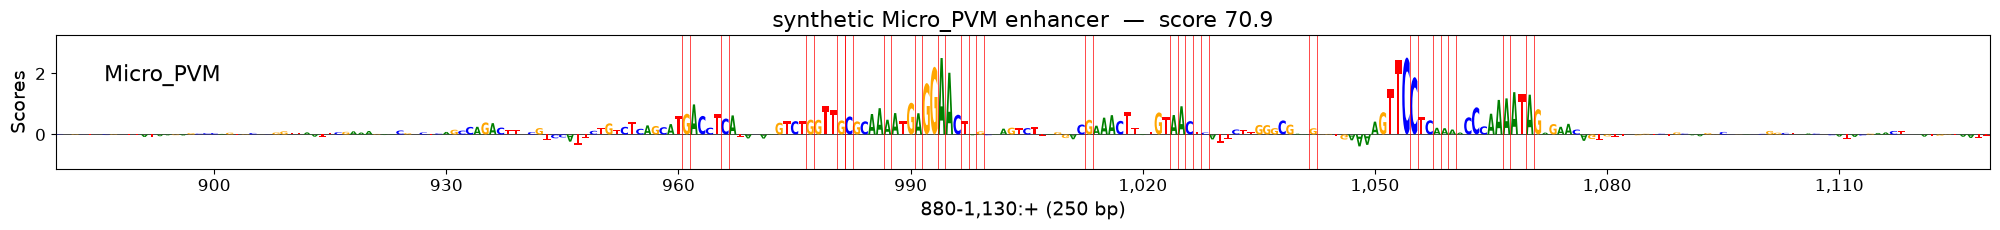

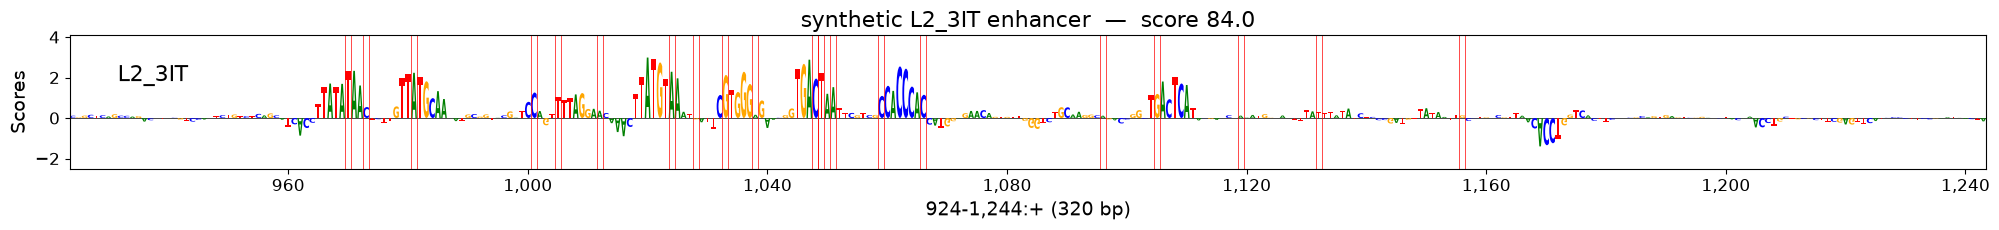

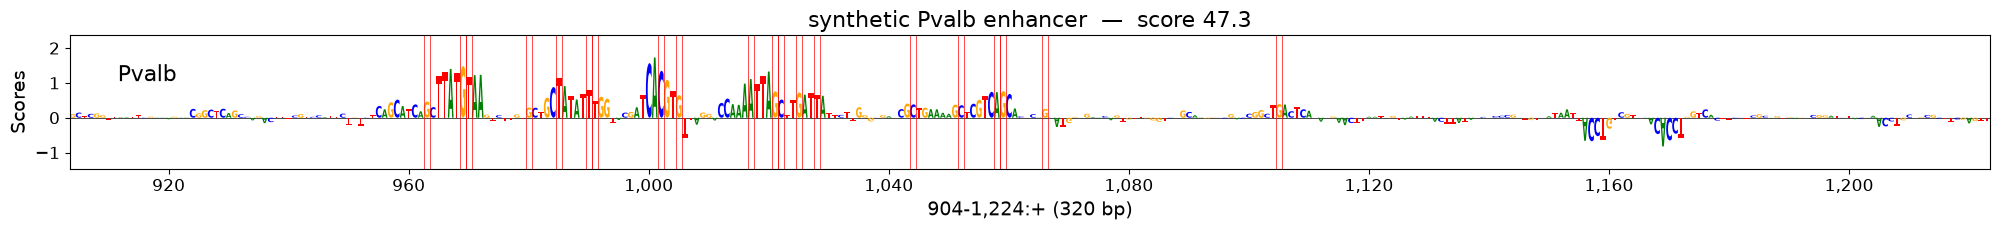

In [15]:
design_spans = {}
for name, k in kept.items():
    idx = cell_types.index(name)
    sc_, oh_ = crested.tl.contribution_scores(k["sequence"], target_idx=idx, model=model,
                                              method="integrated_grad", verbose=False)
    mutated = sorted(p for p, _ in k["record"]["changes"] if p >= 0)
    design_spans[name] = motif_span(sc_, oh_, class_index=0, min_span=250)
    plot_contributions(
        sc_, oh_,
        labels=f"synthetic {name} enhancer  —  score {k['score']:.1f}",
        class_labels=[name],
        span=design_spans[name],
        highlight_positions=[(q, q + 1) for q in mutated],
        width=20, height=2.5,
    )

Each design concentrates its contribution into a few short stretches inside the mutated window, exactly as a real enhancer does. Evolution did not scatter its mutations: it built a small number of binding sites.

Look at the microglia design in particular. It has two tall blocks: around position 990 it reads `GCAAAATGAGGAACT`, carrying the `GGAA` core of an `ETS`/PU.1 site, and around 1,055 a second block containing `AGTTTC` — an `IRF` site. Those are the two words part 1 found in real microglial enhancers, and the model wrote both, unprompted, into DNA that never existed. We gave it a number to maximise, not a motif to use.

**Question**: The designs for the two neuronal targets reach high scores too. Looking at their letters, can you tell which words they are built from as easily as for microglia? What does your answer suggest about why their designs were less specific?

### Step 7: Watching the binding sites being built

The plots above are finished products. More interesting is *how* they got there, because the mutations are not independent: each one is chosen in the context the previous ones created.

So let us replay each run. We rebuild the sequence as it looked after every single mutation, compute its contribution scores, and stack the rounds on top of each other as an image. Each row is one round, each column one position in the DNA. The **colour** says which nucleotide is there, and the **opacity** says how much the model relies on it: invisible means ignored, solid means decisive.

Reading a column downwards shows one position's history. Reading the image as a whole, you watch binding sites condense out of nothing.

One detail about the shading, because it matters for what you can conclude. The prediction grows several hundred-fold over the twenty rounds, so a single scale for the whole image would leave the early rounds blank. Scaling every row to its own maximum has the opposite problem: it would make the random noise of round 1 look as decisive as a finished binding site. We therefore scale each row by its own maximum but never by less than a fraction of the largest value anywhere in the run. Early rounds stay faint because they genuinely carry little; later rounds show their internal structure.

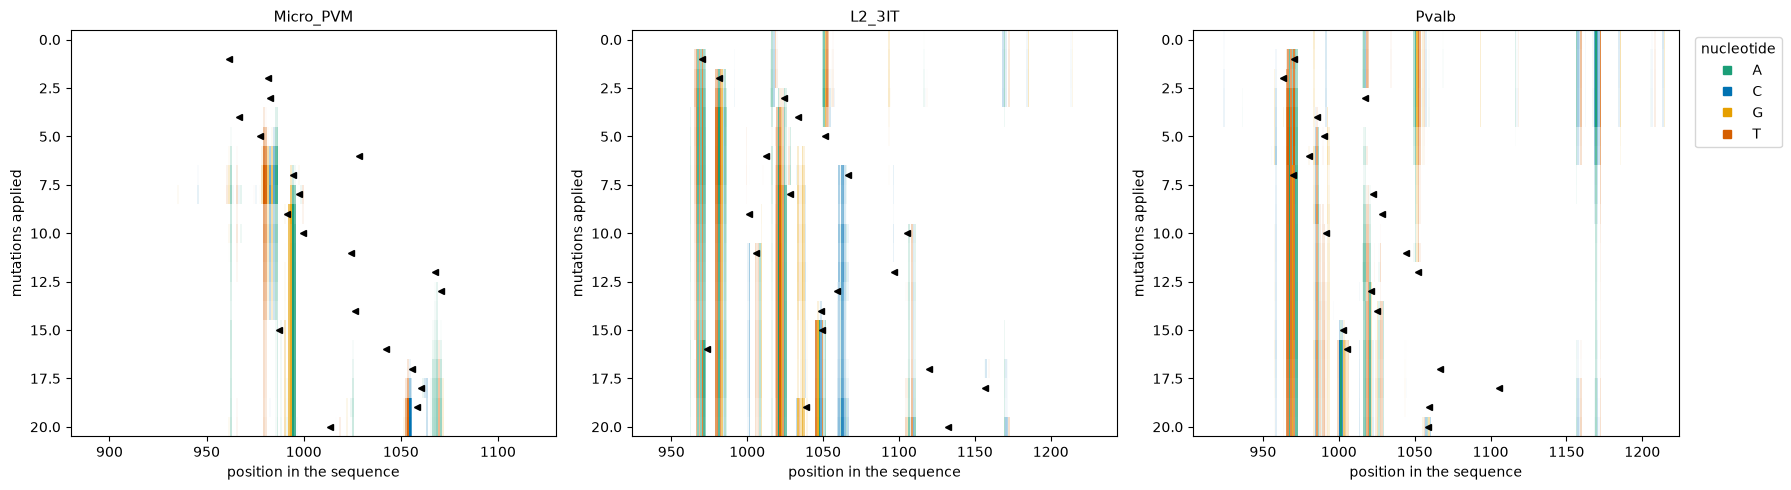

In [16]:
BASE_COLOURS = {"A": "#1B9E77", "C": "#0072B2", "G": "#E69F00", "T": "#D55E00"}

def replay_heatmap(name, ax):
    """Rows are rounds of evolution, columns positions; colour = base, opacity = contribution."""
    record = kept[name]["record"]
    applied = [c for c in record["changes"] if c[0] >= 0]
    sequences = [sequence_after(record, n) for n in range(len(applied) + 1)]
    scores, one_hots = crested.tl.contribution_scores(
        sequences, target_idx=cell_types.index(name), model=model,
        method="integrated_grad", verbose=False)

    lo, hi = design_spans[name]
    image = np.zeros((len(sequences), hi - lo, 4))
    tracks = np.array([(scores[r, 0] * one_hots[r]).sum(axis=1)[lo:hi]
                       for r in range(len(sequences))])
    # Scaling needs care. A single global scale leaves the early rounds blank, because the
    # prediction grows several hundred-fold; scaling every row to its own maximum does the
    # opposite and blows up the noise of the first rounds. So we scale each row by its own
    # maximum, but never by less than a fraction of the largest value in the whole run.
    floor = 0.15 * np.abs(tracks).max()
    scale = np.maximum(np.abs(tracks).max(axis=1, keepdims=True), floor)
    strength = np.abs(tracks) / scale
    opacity = np.clip((strength - 0.25) / 0.75, 0, 1) ** 0.8   # hide the low-level wash
    for r in range(len(sequences)):
        bases = one_hots[r].argmax(axis=1)[lo:hi]
        for j, b in enumerate(bases):
            image[r, j, :3] = mcolors.to_rgb(BASE_COLOURS["ACGT"[b]])
            image[r, j, 3] = opacity[r, j]
    ax.imshow(image, aspect="auto", interpolation="nearest",
              extent=[lo, hi, len(sequences) - 0.5, -0.5])
    for n, (position, _) in enumerate(applied, start=1):
        if lo <= position < hi:
            ax.plot(position + 0.5, n, marker="<", color="black", markersize=4, clip_on=False)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("position in the sequence")
    ax.set_ylabel("mutations applied")

fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 5))
for ax, name in zip(np.atleast_1d(axes), TARGETS.values()):
    replay_heatmap(name, ax)
handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=b)
           for b, c in BASE_COLOURS.items()]
axes[-1].legend(handles=handles, title="nucleotide", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Read the microglia panel downwards and you can watch the enhancer being assembled.

For the first two or three rounds there is nothing: a faint, even wash, which is what random DNA looks like to the model. Then a **dark column appears around position 985** and, once there, it stays for every remaining row — the model has found something it will rely on from here to the end. Around round 12 a **second column appears near 1,055**, and the design finishes with two solid blocks separated by quiet sequence.

Those are the two sites we read letter by letter in Step 6: the `ETS`/PU.1 word first, the `IRF` word second. The heatmap adds the one thing the logo could not show — *when* each appeared, and that neither faded once built.

The black markers trace the mutations. They march steadily down and to the right, clustering first around the position where the first column forms and only later moving out to the second. The optimiser finishes one site before starting another; it does not work on both at once.

Compare the three panels and the same shape appears in all of them, which is worth noting because the three designs ended up with very different specificity. Whatever makes an `L2_3IT` design less exclusive than a microglial one, it is not a difference in how the sites get built.

**Question**: A column that appears early and stays is easy to interpret. What would it mean if a column appeared, persisted for several rounds, and then faded?

## Part 4: Rewriting a natural enhancer

### Step 8: Convert an enhancer from one cell type to another

Starting from random DNA shows what the model considers a microglia enhancer. A sharper question is: **how far apart are two cell types?** If an oligodendrocyte enhancer can be turned into a microglial one with a few mutations, the two codes are close; if it takes many, they are far apart.

We start from the most oligodendrocyte-specific region of part 1 and evolve the **same** sequence towards each of our three targets. Using one starting point for all three makes the comparison fair: whatever differences appear are differences between the destinations, not between the starting materials.

In [17]:
start_region = predictions[predictions["best_cell_type"] == "Oligo"].nlargest(1, "specificity").index[0]
start_seq = crested.utils.fetch_sequences(start_region)[0]
print(start_region, predictions.loc[start_region, ["Oligo"] + list(TARGETS.values())].round(1).to_dict())

conversion_file = RESULTS / "designed_conversion.npz"
saved = cached(conversion_file, [f"{k}_{s}" for k in TARGETS.values() for s in ("seq", "steps")])
if saved is not None:
    conversions = {k: {"sequence": saved[f"{k}_seq"][0], "steps": saved[f"{k}_steps"][0]}
                   for k in TARGETS.values()}
else:
    conversions = {}
    for name in TARGETS.values():
        print(f"converting towards {name} ...")
        steps_, seqs_ = crested.tl.design.in_silico_evolution(
            n_mutations=15, target=cell_types.index(name), model=model,
            starting_sequences=[start_seq], target_len=TARGET_LEN, return_intermediate=True,
        )
        conversions[name] = {"sequence": seqs_[0], "steps": steps_[0]}
    np.savez(conversion_file,
             **{f"{k}_seq": np.array([v["sequence"]], dtype=object) for k, v in conversions.items()},
             **{f"{k}_steps": np.array([v["steps"]], dtype=object) for k, v in conversions.items()})

chr5:114578886-114581000 {'Oligo': 134.2, 'Micro_PVM': 5.2, 'L2_3IT': 6.3, 'Pvalb': 6.4}


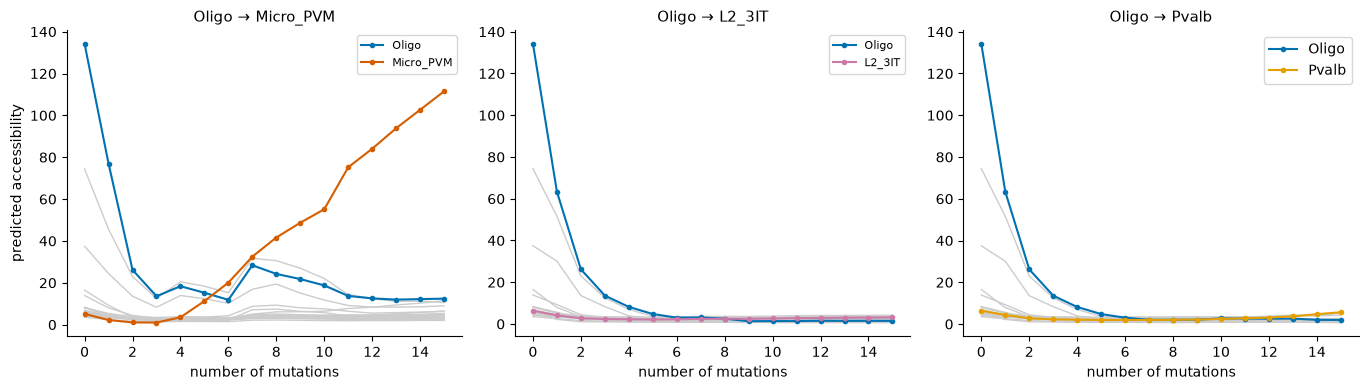

,Micro_PVM,L2_3IT,Pvalb
L2_3IT,NaN,3.1,NaN
Micro_PVM,111.5,NaN,NaN
Oligo,12.4,1.5,1.9
Pvalb,NaN,NaN,5.6


In [18]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(4.6 * len(TARGETS), 4), sharex=True)
for ax, name in zip(axes, TARGETS.values()):
    steps = pd.DataFrame(conversions[name]["steps"]["predictions"], columns=cell_types)
    for cell_type in cell_types:
        if cell_type not in (name, "Oligo"):
            ax.plot(steps.index, steps[cell_type], color=GREY, lw=1, zorder=0)
    for cell_type in ["Oligo", name]:
        ax.plot(steps.index, steps[cell_type], marker="o", markersize=3,
                color=cell_colour(cell_type), label=cell_type, zorder=3)
    ax.set_xlabel("number of mutations")
    ax.set_title(f"Oligo → {name}", fontsize=11)
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("predicted accessibility")
plt.tight_layout()
plt.legend()
plt.show()

pd.DataFrame({name: pd.DataFrame(conversions[name]["steps"]["predictions"],
                                 columns=cell_types)[["Oligo", name]].iloc[-1]
              for name in TARGETS.values()}).round(1)

One conversion works and two fail, and the pattern is more informative than three successes would have been.

**Oligo → Micro_PVM works cleanly.** The oligodendrocyte score collapses from 134 to about 12 while the microglia score climbs from 5 to 111, and the two curves cross at around the seventh mutation. Fifteen changes in 2,114 bp — 0.7% of the sequence — are enough to switch which cell type the model thinks this enhancer belongs to.

**Oligo → L2_3IT and Oligo → Pvalb do not.** In both, the oligodendrocyte score crashes just as fast, down to about 2. But the target never rises: it *falls*. `L2_3IT` starts at 6.3 and ends at 3.1, `Pvalb` starts at 6.4 and ends at 5.6 — after fifteen mutations aimed at them, both targets are worse off than before we began. The sequence stopped being an oligodendrocyte enhancer and did not become anything else.

Why the difference? Not because neuronal enhancers are impossible to design — Step 5 built an `L2_3IT` enhancer scoring 84 from random DNA. The difference is the **starting point and the budget**. Beginning from a strong oligodendrocyte enhancer, the cheapest early gains all come from demolition: every SOX site removed raises "target minus the others" immediately. By the time the oligodendrocyte signal is gone, the mutation budget is nearly spent, and what remains is not enough to assemble a neuronal programme. Microglia escape this because their code needs only a couple of distinctive, easily-built sites.

So the honest conclusion is narrower than "enhancer identity is easy to switch". Converting *towards microglia* is easy. Converting towards a neuron type, with this budget and this starting sequence, is not — and the failure looks exactly like the failed design in Step 5: destruction standing in for construction.

**Question**: How would you test whether the two failures are a budget problem? Name the single parameter you would change, and what result would convince you.

We follow the `Micro_PVM` conversion from here on, because it is the one whose motifs we already know from part 1. Let's look at which positions were changed.

In [19]:
changes = [(p, n) for p, n in conversions[TARGET]["steps"]["changes"] if p >= 0]
pd.DataFrame({
    "step": range(1, len(changes) + 1),
    "position": [p for p, _ in changes],
    "original": [start_seq[p] for p, _ in changes],
    "new": [n for _, n in changes],
})

,step,position,original,new
0,1,1020,A,T
1,2,1052,T,G
2,3,994,G,A
3,4,996,G,T
4,5,991,A,G
5,6,1034,G,C
6,7,1018,G,C
7,8,988,G,A
8,9,1010,C,A
9,10,1046,C,A


**Question**: The mutations are not spread evenly. What does their clustering suggest about what is being destroyed and what is being created?

### Step 8b: What was destroyed, and what was built?

The table tells us *where* the changes are. To see *what* they did we need the contribution scores before and after — and we need them for **both** cell types, because the conversion has two halves: the oligodendrocyte code has to be taken apart and the microglial one put together.

We compute four tracks: the original enhancer and the converted one, each read as an oligodendrocyte enhancer and as a microglia enhancer.

In [20]:
before_scores, before_oh = crested.tl.contribution_scores(
    start_seq, target_idx=[cell_types.index("Oligo"), TARGET_IDX],
    model=model, method="integrated_grad", verbose=False,
)
after_scores, after_oh = crested.tl.contribution_scores(
    conversions[TARGET]["sequence"], target_idx=[cell_types.index("Oligo"), TARGET_IDX],
    model=model, method="integrated_grad", verbose=False,
)

# zoom onto the window the mutations landed in, using the same window for both plots
conversion_span = motif_span(before_scores, before_oh, class_index=0, min_span=250)
low, high = min(p for p, _ in changes), max(p for p, _ in changes)
conversion_span = (min(conversion_span[0], low - 30), max(conversion_span[1], high + 30))
conversion_span = (max(0, conversion_span[0]), min(WIDTH, conversion_span[1]))
print("mutations between", low, "and", high, "| showing", conversion_span)

mutations between 988 and 1115 | showing (882, 1159)


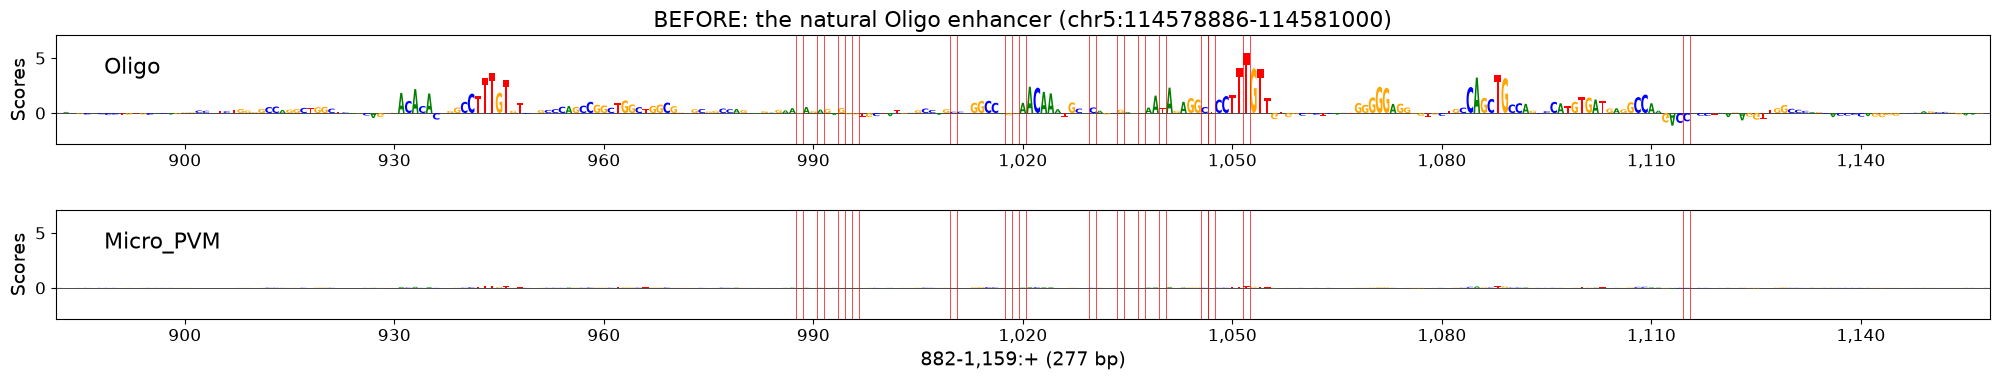

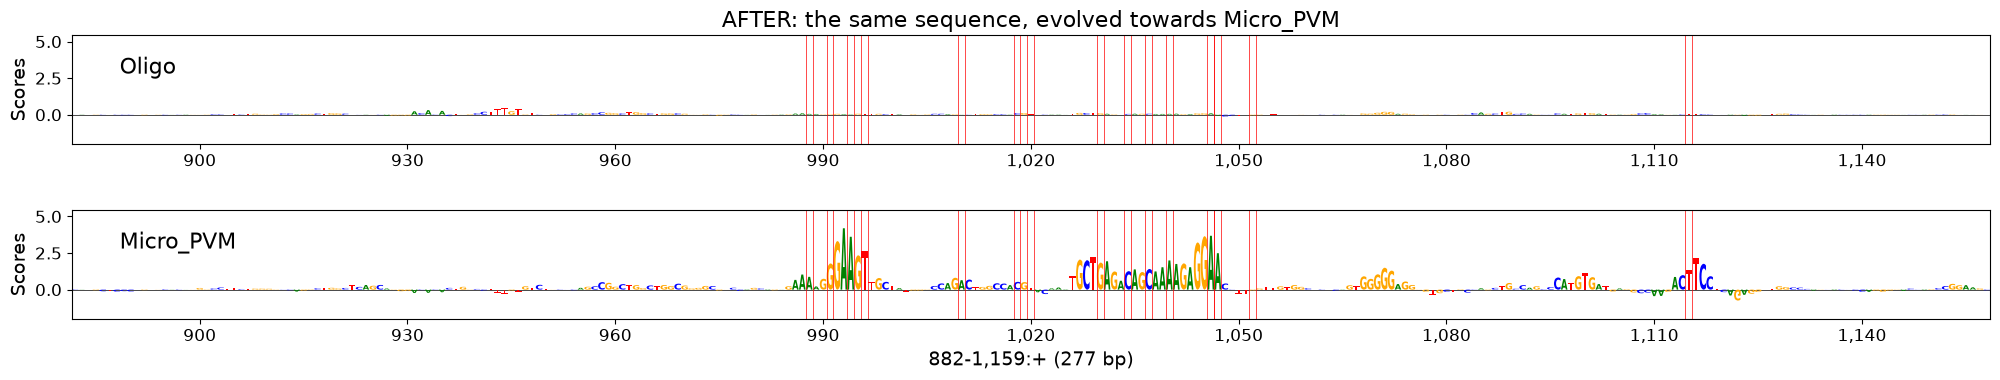

In [21]:
plot_contributions(
    before_scores, before_oh,
    labels=f"BEFORE: the natural Oligo enhancer ({start_region})",
    class_labels=["Oligo", TARGET],
    span=conversion_span,
    highlight_positions=[(p, p + 1) for p, _ in changes],
    width=20, height=4,
)
plot_contributions(
    after_scores, after_oh,
    labels=f"AFTER: the same sequence, evolved towards {TARGET}",
    class_labels=["Oligo", TARGET],
    span=conversion_span,
    highlight_positions=[(p, p + 1) for p, _ in changes],
    width=20, height=4,
)

Before reading the letters, one number is worth having. The mutations all landed in a narrow stretch. Did the oligodendrocyte code disappear only *there*, or everywhere?

In [22]:
def total_contribution(scores, one_hot, class_index, lo, hi):
    """How much contribution the model places in a stretch of the sequence."""
    track = np.abs((scores[0, class_index] * one_hot[0]).sum(axis=1))
    return float(track[lo:hi].sum())

lo, hi = low - 5, high + 5          # the stretch the mutations landed in
summary = pd.DataFrame(
    {"inside the mutated stretch": [total_contribution(before_scores, before_oh, 0, lo, hi),
                                    total_contribution(after_scores, after_oh, 0, lo, hi)],
     "everywhere else": [total_contribution(before_scores, before_oh, 0, 0, lo)
                         + total_contribution(before_scores, before_oh, 0, hi, WIDTH),
                         total_contribution(after_scores, after_oh, 0, 0, lo)
                         + total_contribution(after_scores, after_oh, 0, hi, WIDTH)]},
    index=["before", "after"],
).round(1)
target_steps = pd.DataFrame(conversions[TARGET]["steps"]["predictions"], columns=cell_types)
summary["Oligo prediction"] = [predictions.loc[start_region, "Oligo"], target_steps["Oligo"].iloc[-1]]
summary

,inside the mutated stretch,everywhere else,Oligo prediction
before,108.8,86.8,134.173900
after,7.4,14.3,12.433414


The oligodendrocyte signal did not disappear only where we edited. Inside the mutated stretch it fell from about 109 to 7; **everywhere else, where we changed nothing at all, it fell from about 87 to 14.** Fifteen mutations in a 130 bp stretch emptied the whole 2,114 bp of oligodendrocyte meaning.

That deserves care, because the obvious reading is the wrong one. We did not reach out and destroy a SOX site 100 bp away. Contribution scores answer the question *"how much does this nucleotide matter for this prediction?"*, and they add up, roughly, to the prediction itself. The oligodendrocyte prediction fell from 134 to 12, so there is almost nothing left to attribute — anywhere. A site that is still physically present in the sequence goes quiet because the question it used to answer is no longer being asked.

**This is the single most important caveat about contribution scores in this whole practical.** They are not a property of a binding site. They are a property of a site *in a sequence*, *for a cell type*. The same letters can be essential in one context and invisible in another, and the plot cannot tell you which situation you are in unless you also look at the prediction.

Now read the letters themselves.

**What was destroyed.** Look at the BEFORE plot around positions 1,045–1,055: a tall `CCTTTGTT`, which is a `HMG`/SOX site — the oligodendrocyte word from part 1, read on the reverse strand. Three of our fifteen mutations (1,046, 1,047 and 1,052) land directly inside it. Another cluster of mutations falls on the smaller peak around 1,018–1,025. The search did not spread its changes over the region: it went for the sites that were carrying the oligodendrocyte prediction.

**What was built.** In the AFTER plot the microglia row has tall stretches where it was flat before. Around position 990 it reads `AAAGGGAAGT`; around 1,040, `CAAAAGAGGAA`; and at 1,113, a smaller `ACTTCC`. Every one of them carries `GGAA`, the core of an `ETS`/PU.1 site — the last one on the reverse strand, which is why it reads backwards. Compare the middle one with cluster 27 of part 1, `AAAGAGGAAGT`, the most microglia-specific motif we found there: it is almost letter for letter the same word.

So the model did not invent a private solution. Asked to make this sequence microglial, it wrote the motif we had independently read out of real microglial enhancers — three times.

**What this tells us about the regulatory code.** Three things, and the third is the interesting one.

1. **The two codes occupy the same real estate.** The microglial sites were not built in the empty 90% of the sequence. They were written on top of the oligodendrocyte sites, in the same 60 bp. Whatever makes this stretch of DNA a good place for a binding site — accessibility, flanking composition, position — makes it good for *either* cell type's sites.
2. **Conversion is overwriting, not adding.** You cannot make this sequence microglial by adding PU.1 sites and leaving the SOX sites alone. The optimiser spent much of its budget removing, not building. Cell-type identity here is as much about which words are *absent* as which are present.
3. **Identity is cheap to change and expensive to hold.** Fifteen mutations — 0.7% of the sequence — flipped this enhancer's cell type in the model's view. Yet that enhancer has presumably sat in the mouse genome doing one job for millions of years. What keeps a real enhancer from drifting is selection, not the robustness of its sequence. That is worth remembering when you read that an enhancer is "conserved": it is conserved because variants were removed, not because the code is hard to break.

**Question**: The oligodendrocyte contributions went quiet across the whole region, including at sites we never touched. Suppose instead you had mutated only the distant SOX site at position 945 and left the rest alone. What would you expect the two rows to look like, and what would it tell you about whether these sites work independently?

## Part 5: Building with the motifs discovered in part 1

### Step 9: Turn the motifs of part 1 into building blocks

Evolution is powerful but indirect: it tells us what the model wants, not what we believe. A more controlled experiment is to **insert specific motifs ourselves** and see how the prediction responds. This is the in-silico version of a classic molecular biology experiment: put a binding site into a reporter construct and measure the effect.

The motifs we insert are the ones **we discovered in part 1**. There, TF-MINDI grouped the important sequence stretches into clusters, each with a consensus motif and a cell type that uses it. We load those results back in.

A pattern is a matrix of nucleotide probabilities. To insert it as DNA we take its **informative core**: trim the uncertain flanking positions and keep the most likely nucleotide at each remaining position.

In [23]:
patterns = tm.load_patterns(RESULTS / "patterns_biccn.pkl")
clusters = pd.read_csv(RESULTS / "seqlet_clusters_per_cell_type.csv", index_col=0)

def motif_core(pattern, min_information=0.2):
    """The consensus of a pattern's informative core, and how informative it is."""
    ppm = np.asarray(pattern.ppm)
    if ppm.shape[0] == 4:
        ppm = ppm.T
    start, end = pattern.ic_trim(min_information)
    if end <= start:
        return "", 0.0
    core = ppm[start:end]
    return ("".join("ACGT"[i] for i in core.argmax(axis=1)),
            float(np.mean(np.asarray(pattern.ic())[start:end])))

building_blocks = pd.DataFrame([
    {"cluster": cluster,
     "TF family": pattern.dbd,
     "motif": motif_core(pattern)[0],
     "information": round(motif_core(pattern)[1], 2),
     "cell type": clusters.loc[int(cluster), "cell type"],
     "share": clusters.loc[int(cluster), "share"]}
    for cluster, pattern in patterns.items() if pattern is not None
]).set_index("cluster")

usable = building_blocks[(building_blocks["information"] >= 0.5)
                         & (building_blocks["motif"].str.len() >= 5)]
usable.sort_values("share", ascending=False).head(12)

,TF family,motif,information,cell type,share
cluster,,,,,
33,bHLH,GAAAGTACAGCTGTATAAACAAATA,0.86,VLMC,0.82
28,"ETS, Homeobox",ACTTCCTCTTT,0.82,Micro_PVM,0.66
19,HMG,AAAAGGCCCTTTGT,0.72,OPC,0.53
32,TEA,ACATTCCT,1.34,VLMC,0.50
22,Fork_head,AAAAAAAACA,0.85,VLMC,0.46
5,zf-C2H2,AAACTAGGTCA,1.01,Astro,0.39
14,bHLH,GCAGCTG,1.41,SstChodl,0.39
24,bHLH,CCATCTGTT,1.27,L5_6NP,0.39
17,Pou,TTAATATGCAAAT,0.71,L5ET,0.36


This table is the bridge between the two notebooks. A good building block has to satisfy two conditions, and the table shows both: it must be **used mostly by one cell type** (a high `share`) and it must be a **real motif** (a high `information`; the low-information clusters of part 1 score near zero and are already filtered out here).

We take the two best blocks for each of our three target cell types.

In [24]:
def best_blocks(cell_type, n=2):
    return usable[usable["cell type"] == cell_type].nlargest(n, "share")

for name in TARGETS.values():
    print(f"{name} building blocks:")
    print(best_blocks(name)[["TF family", "motif", "share"]].to_string(), "\n")

Micro_PVM building blocks:
             TF family        motif  share
cluster                                   
28       ETS, Homeobox  ACTTCCTCTTT   0.66 

L2_3IT building blocks:
        TF family         motif  share
cluster                               
10        zf-C2H2     TGTGGGAGG   0.33
21        zf-C2H2  ACAAAATGTTCT   0.17 

Pvalb building blocks:
        TF family     motif  share
cluster                           
29           bHLH  GTCACGTG   0.26
31        TF_bZIP    TGCTGA   0.25 



### Step 10: Can these motifs steer a sequence to a chosen cell type?

Now the actual experiment, and it is a **prediction, not a demonstration**. Part 1 told us how exclusive each motif is — the `share` column printed above. If the enhancer code works the way part 1 suggested, then inserting a motif should steer a sequence towards a cell type *in proportion to how exclusive that motif was*. Microglia's block has a share of 0.66; the neuronal blocks sit at 0.33 and below, barely above the 0.05 you would get by chance with 19 cell types. So we should expect one clear success and two weak results — and if we get something else, part 1 was wrong somewhere.

Two changes from the naive version of this experiment. We insert **three copies** of each motif rather than one, because Step 12 will show that single sites do very little. And we will read the result as a **fold change over the random background**, not as a raw score, because the background is far from flat: the model considers random DNA of genomic composition to be a weak neuronal enhancer already.

In [25]:
COPIES_PER_MOTIF = 3

def insert_blocks(blocks, target_cell_type, n_sequences=3):
    """Insert several copies of each motif; return the mean prediction before and after."""
    np.random.seed(0)
    patterns = {f"cluster {c}": m for c, m in blocks["motif"].items()}
    steps, sequences = crested.tl.design.motif_insertion(
        patterns=patterns,
        insertions_per_pattern={k: COPIES_PER_MOTIF for k in patterns},
        model=model, target=cell_types.index(target_cell_type), n_sequences=n_sequences,
        target_len=TARGET_LEN, acgt_distribution=acgt_distribution, return_intermediate=True,
    )
    trace = pd.DataFrame(np.mean([s["predictions"] for s in steps], axis=0), columns=cell_types)
    return trace, steps, sequences

insertions = {}
for name in TARGETS.values():
    blocks = best_blocks(name)
    trace, steps, sequences = insert_blocks(blocks, name)
    insertions[name] = {"blocks": blocks, "trace": trace, "steps": steps, "sequences": sequences}
    print(f"{name}: {len(blocks)} motif(s) x {COPIES_PER_MOTIF} copies, "
          f"best share {blocks['share'].max():.2f}")

Micro_PVM: 1 motif(s) x 3 copies, best share 0.66


L2_3IT: 2 motif(s) x 3 copies, best share 0.33


Pvalb: 2 motif(s) x 3 copies, best share 0.26


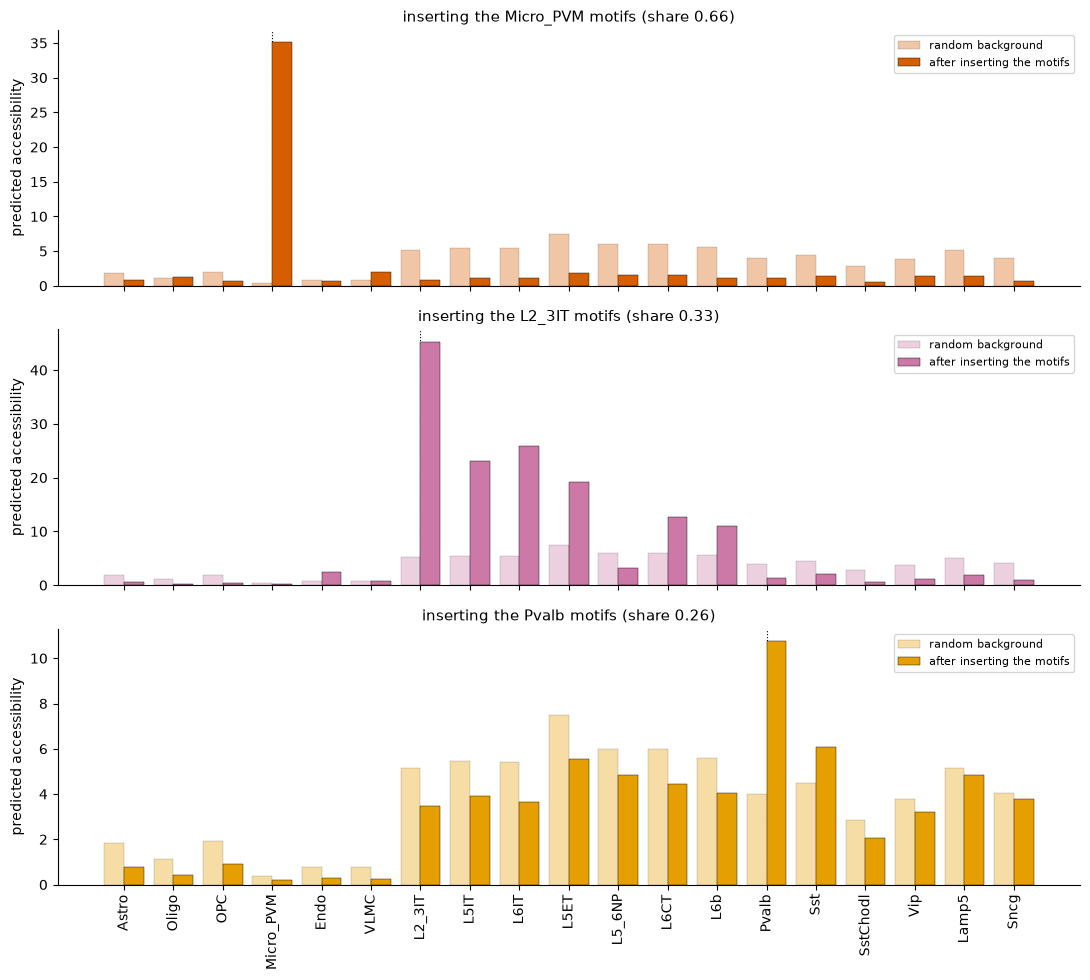

In [26]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 3.3 * len(TARGETS)), sharex=True)
x = np.arange(len(CELL_TYPES))
for ax, name in zip(axes, TARGETS.values()):
    trace = insertions[name]["trace"]
    before, after = trace.iloc[0], trace.iloc[-1]
    ax.bar(x - 0.2, before[CELL_TYPES], width=0.4, label="random background",
           color=cell_colour(name), alpha=0.35, edgecolor="black", linewidth=0.3)
    ax.bar(x + 0.2, after[CELL_TYPES], width=0.4, label="after inserting the motifs",
           color=cell_colour(name), edgecolor="black", linewidth=0.3)
    ax.axvline(CELL_TYPES.index(name), color="black", lw=0.8, ls=":", zorder=0)
    ax.set_ylabel("predicted accessibility")
    ax.set_title(f"inserting the {name} motifs "
                 f"(share {insertions[name]['blocks']['share'].max():.2f})", fontsize=11)
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xticks(x, CELL_TYPES, rotation=90)
plt.tight_layout()
plt.show()

The raw scores are hard to compare across panels, because the background differs by more than twenty-fold between cell types. The fold change puts every cell type on the same footing, and the table says plainly whether the design ended up being *about* its target.

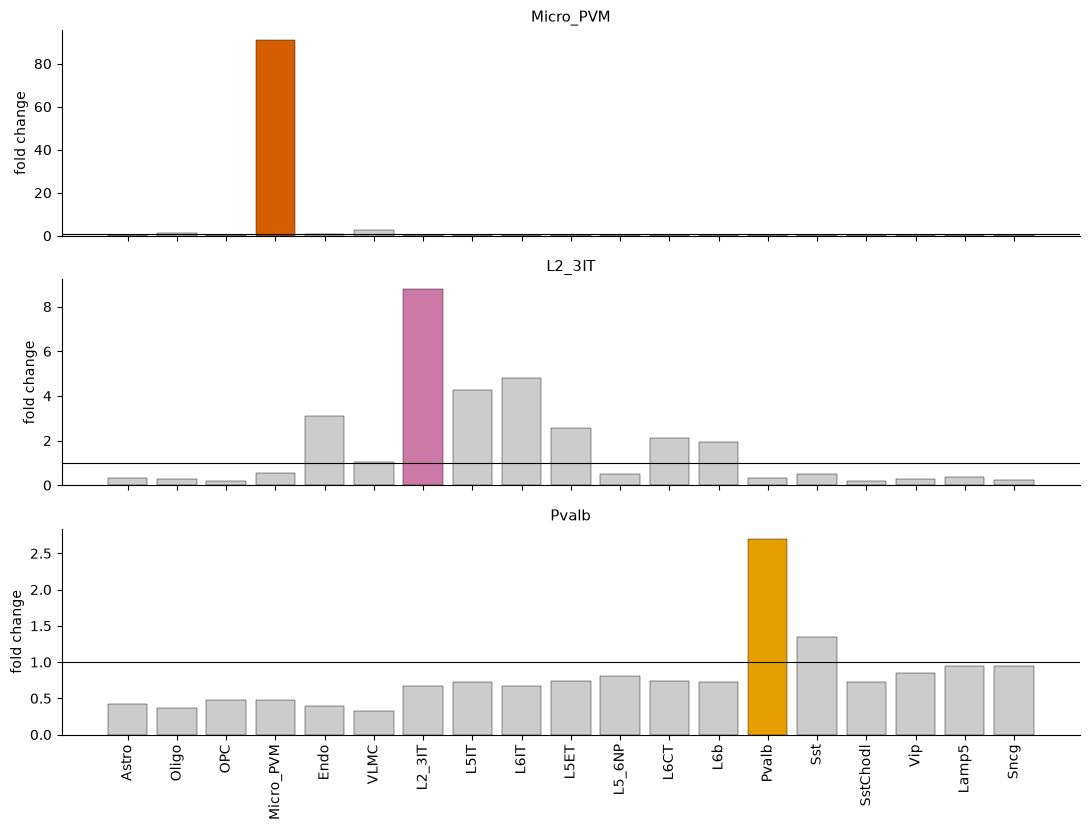

,background,after,fold change,rank of target among 19,highest cell type
target,,,,,
Micro_PVM,0.39,35.13,91.1,1,Micro_PVM
L2_3IT,5.16,45.31,8.8,1,L2_3IT
Pvalb,3.98,10.77,2.7,1,Pvalb


In [27]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 2.8 * len(TARGETS)), sharex=True)
rows = []
for ax, name in zip(axes, TARGETS.values()):
    trace = insertions[name]["trace"]
    fold = (trace.iloc[-1] / trace.iloc[0])[CELL_TYPES]
    ax.bar(x, fold, color=[cell_colour(name) if c == name else GREY for c in CELL_TYPES],
           edgecolor="black", linewidth=0.3)
    ax.axhline(1, color="black", lw=0.8)
    ax.set_ylabel("fold change")
    ax.set_title(f"{name}", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    after = trace.iloc[-1]
    rows.append({"target": name,
                 "background": round(float(trace.iloc[0][name]), 2),
                 "after": round(float(after[name]), 2),
                 "fold change": round(float(fold[name]), 1),
                 "rank of target among 19": int(after.rank(ascending=False)[name]),
                 "highest cell type": after.idxmax()})
axes[-1].set_xticks(x, CELL_TYPES, rotation=90)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("target")

The prediction holds, and it holds quantitatively.

**All three designs end up being about their target.** In every panel the target is rank 1 of 19 after insertion — the sequence is more accessible in the cell type we aimed at than in any other. That is the minimum bar, and the single-copy version of this experiment did not clear it.

**The size of the effect tracks the `share` almost exactly.** Microglia, share 0.66, gains a factor of **91**. Layer 2/3, share 0.33, gains **8.8**. Pvalb, share 0.26, gains **2.7**. Three motifs, three exclusivity values, three fold changes in the same order — this is the prediction from part 1 coming out in a design experiment.

**Specificity follows the same ordering.** In the microglia panel every other bar sits at 1: nothing else moved at all. In the `L2_3IT` panel the target gains 8.8× but `L5IT`, `L6IT` and `L5ET` gain between 2.6 and 4.8× — the relatives come along, at roughly half the rate. In the `Pvalb` panel the target gains 2.7×, `Sst` 1.4×, and **every other cell type drops below 1**: a small, clean push in the right direction rather than a large one.

So "does inserting a motif make a cell-type-specific enhancer?" has a precise answer: *in proportion to how exclusive that motif was in real enhancers*. A motif used by one cell type acts as a switch. A motif shared across a lineage moves the whole lineage. Part 1 measured that exclusivity; part 2 shows it was measuring something real.

**Question**: The microglia block gains 91× from three copies. Would nine copies gain three times as much? Look at the curves in the next step before answering.

### Step 11: Does the model really use the inserted motifs?

A higher score could in principle come from somewhere else in the sequence. To check, we compute contribution scores for one designed sequence per target and highlight where we inserted a motif.

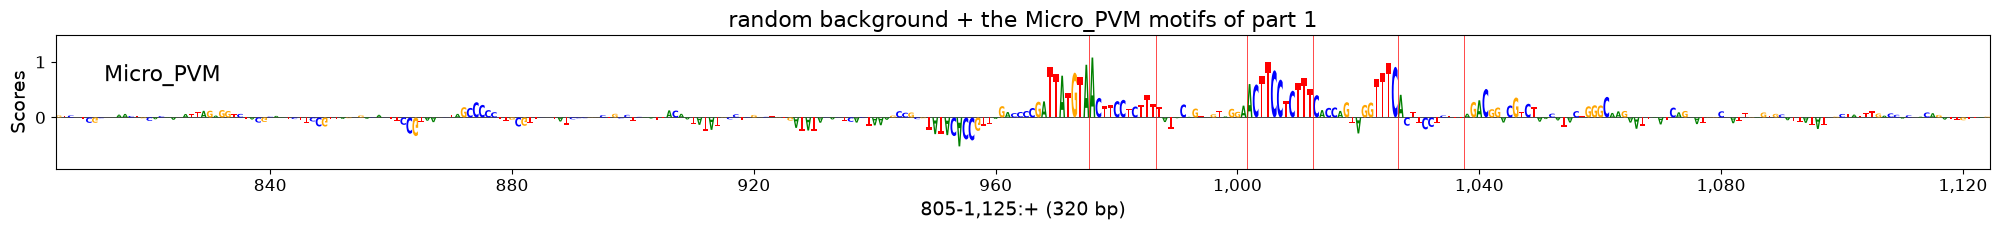

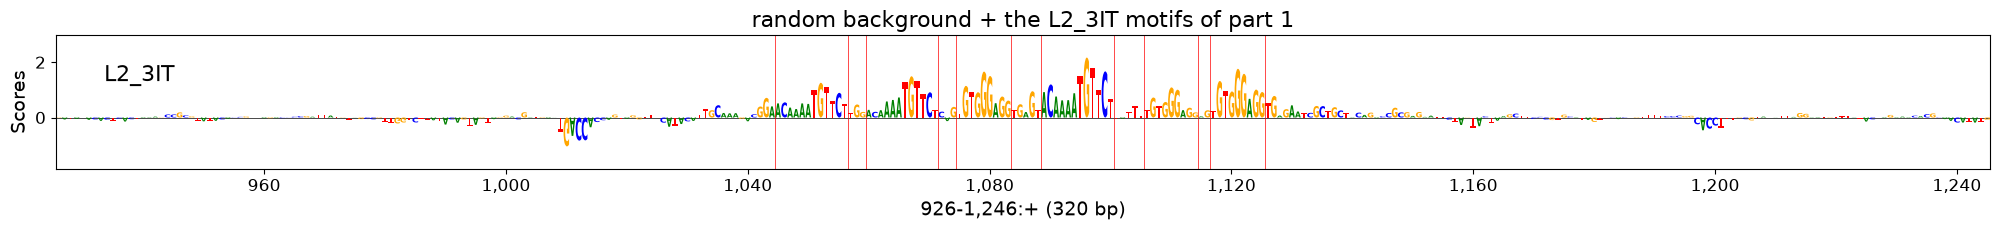

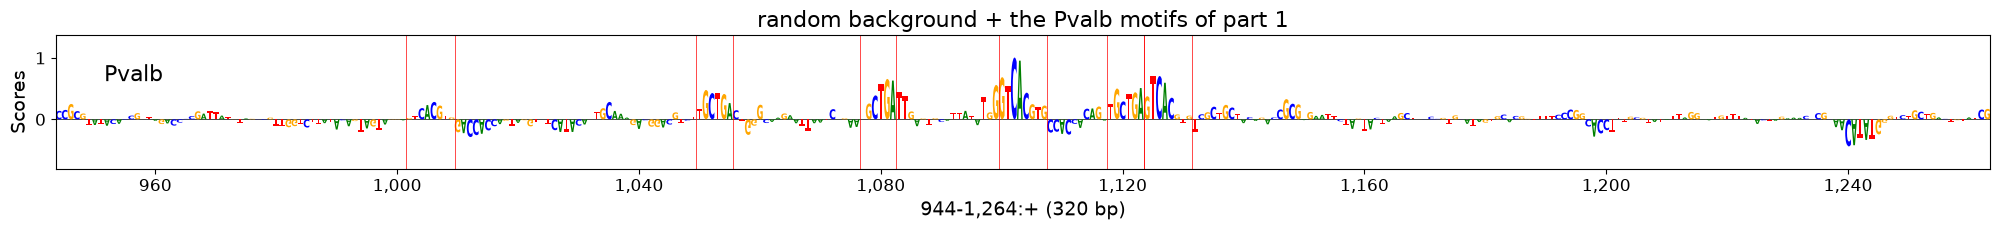

In [28]:
for name in TARGETS.values():
    run = insertions[name]
    sc_, oh_ = crested.tl.contribution_scores(
        run["sequences"][0], target_idx=cell_types.index(name),
        model=model, method="integrated_grad", verbose=False)
    inserted = [(q, q + len(m)) for q, m in run["steps"][0]["changes"] if q >= 0]
    plot_contributions(
        sc_, oh_,
        labels=f"random background + the {name} motifs of part 1",
        class_labels=[name],
        span=motif_span(sc_, oh_, class_index=0, min_span=250),
        highlight_positions=inserted,
        width=20, height=2.5,
    )

In each panel the vertical lines mark where we pasted a motif, and in each the model does put contribution there: the inserted sites are being read, not ignored.

The vertical lines mark where we pasted each copy, and in every panel the model puts contribution on them: the inserted sites are being read, not ignored. In the microglia panel you can pick out all three copies as separate blocks of tall letters.

Compare the vertical scale with Step 6, though. These letters reach about 1.2, against roughly 2.5 in the evolved design — about half, matching the roughly half-sized score (35 against 71). The model recognises the words we inserted, but the sequence around them is still random, and it reads a binding site in proportion to its context.

Notice also the smaller contributions *outside* the marked copies. Random DNA contains partial sites by chance, and once a sequence begins to look like an enhancer the model starts reading those too.

### Step 12: Does the number of motifs matter?

Enhancers often contain several copies of the same binding site. Does the model think more is better? We insert the best motif of each target one to four times, averaging over several random backgrounds, and then look at what the extra copies did to the sequence.

In [29]:
copy_curves, copy_sequences = {}, {}
COPIES = [0, 1, 2, 3, 4]

for name in TARGETS.values():
    blocks = insertions[name]["blocks"]
    cluster = blocks.index[0]
    motif = blocks.loc[cluster, "motif"]
    rows, keep = [], {}
    for n_copies in COPIES:
        np.random.seed(1)
        if n_copies == 0:
            seqs = ["".join(rng.choice(list("ACGT"), WIDTH, p=acgt_distribution))
                    for _ in range(4)]
        else:
            seqs = crested.tl.design.motif_insertion(
                patterns={"motif": motif}, insertions_per_pattern={"motif": n_copies},
                model=model, target=cell_types.index(name), n_sequences=4,
                target_len=TARGET_LEN, acgt_distribution=acgt_distribution,
            )
        seqs = list(seqs)
        keep[n_copies] = seqs[0]
        rows.append(pd.Series(crested.tl.predict(seqs, model, verbose=0).mean(axis=0),
                              index=cell_types, name=n_copies))
    curve = pd.DataFrame(rows); curve.index.name = "copies of the motif"
    copy_curves[name] = curve
    copy_sequences[name] = keep
    print(f"{name}: cluster {cluster} ({blocks.loc[cluster, 'TF family']}) = {motif}")

Micro_PVM: cluster 28 (ETS, Homeobox) = ACTTCCTCTTT


L2_3IT: cluster 10 (zf-C2H2) = TGTGGGAGG


Pvalb: cluster 29 (bHLH) = GTCACGTG


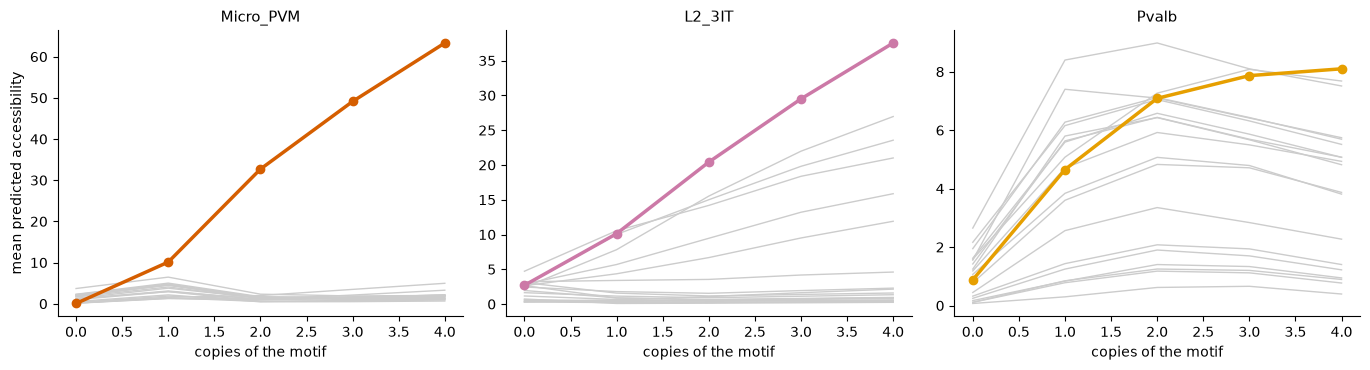

Micro_PVM  L2_3IT  Pvalb
          copies of the motif                          
Micro_PVM 0                     0.100000     1.8    1.2
          1                    10.100000     4.6    3.1
          2                    32.700001     1.3    1.0
          3                    49.099998     1.1    1.3
          4                    63.299999     1.2    1.8
L2_3IT    0                     0.700000     2.7    1.6
          1                     0.100000    10.1    1.1
          2                     0.100000    20.4    0.9
          3                     0.200000    29.5    1.1
          4                     0.300000    37.5    1.3
Pvalb     0                     0.100000     1.2    0.9
          1                     0.300000     5.8    4.7
          2                     0.600000     6.4    7.1
          3                     0.700000     5.7    7.9
          4                     0.400000     4.8    8.1

In [30]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(4.6 * len(TARGETS), 3.8), sharex=True)
for ax, name in zip(axes, TARGETS.values()):
    curve = copy_curves[name]
    for cell_type in cell_types:
        on_target = cell_type == name
        ax.plot(curve.index, curve[cell_type],
                color=cell_colour(name) if on_target else GREY,
                marker="o" if on_target else None,
                lw=2.5 if on_target else 1, zorder=3 if on_target else 1)
    ax.set_xlabel("copies of the motif")
    ax.set_title(name, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mean predicted accessibility")
plt.tight_layout()
plt.show()

pd.concat({name: curve[list(TARGETS.values())] for name, curve in copy_curves.items()}).round(1)

The copy number changes the score, but the plot does not say *why*. Does a second copy add a second site the model reads, or does it strengthen the first one? Contribution scores for the same sequences answer that: below, one sequence per copy number, for the target we have followed throughout.

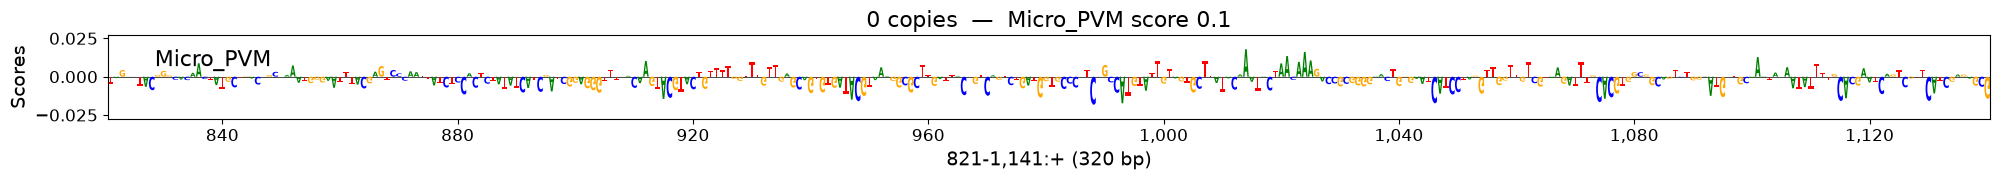

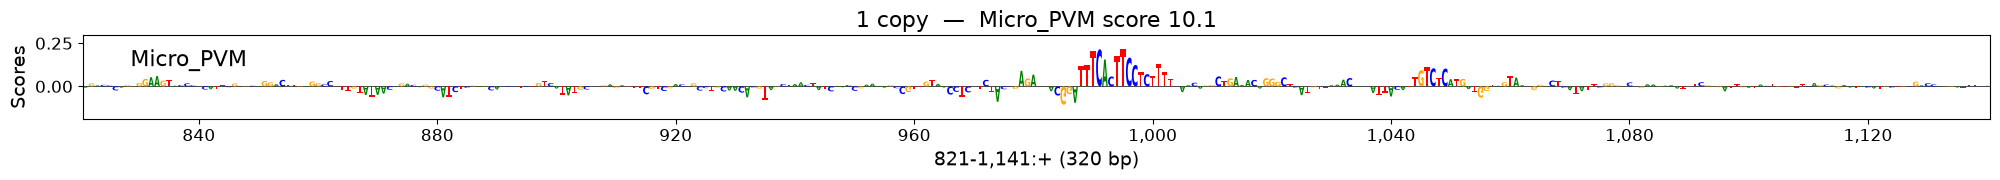

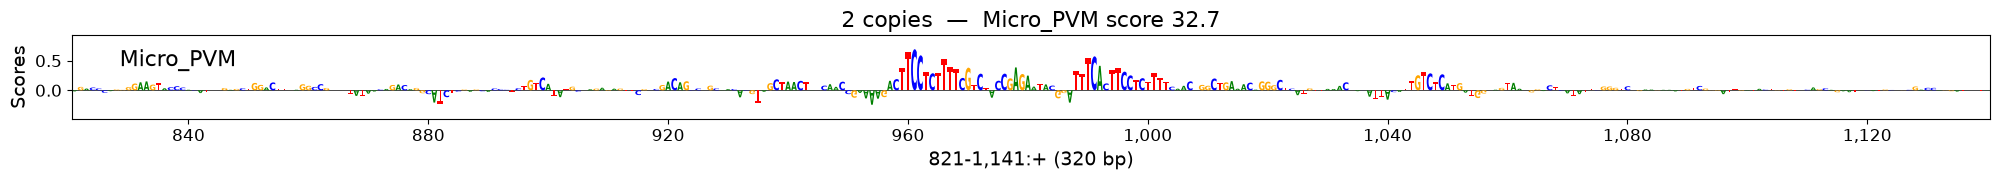

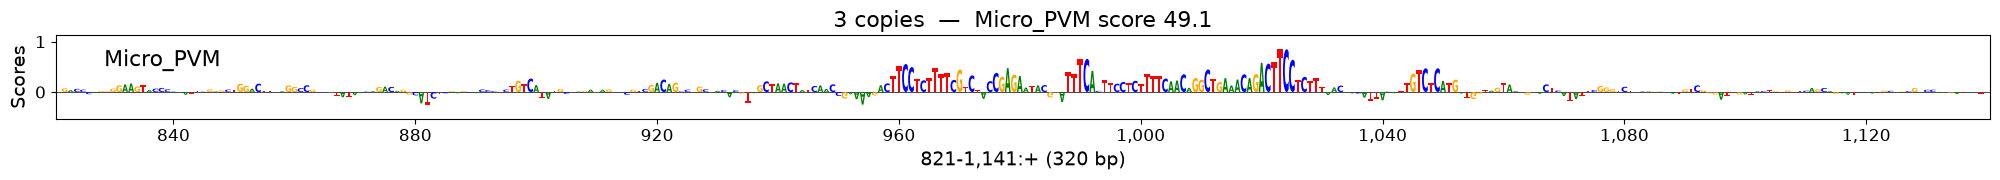

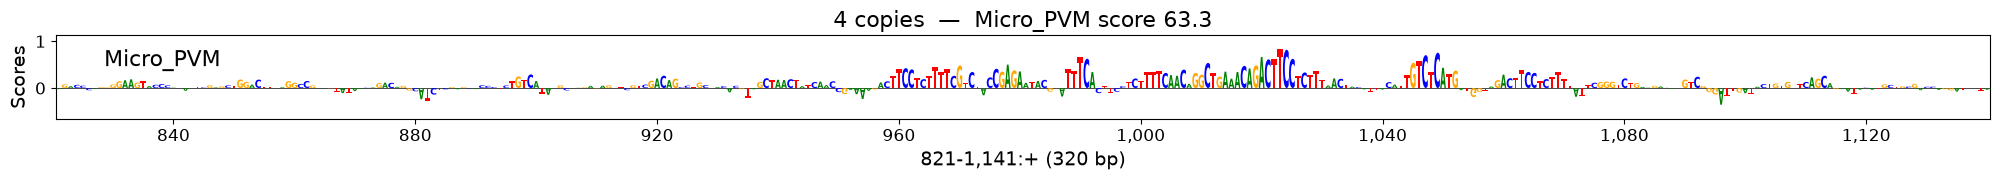

In [31]:
sequences = [copy_sequences[TARGET][n] for n in COPIES]
copy_scores, copy_one_hot = crested.tl.contribution_scores(
    sequences, target_idx=TARGET_IDX, model=model, method="integrated_grad", verbose=False)
span = motif_span(copy_scores, copy_one_hot, class_index=0, sequence_index=len(COPIES) - 1,
                  min_span=300)

for i, n_copies in enumerate(COPIES):
    score = copy_curves[TARGET][TARGET].loc[n_copies]
    plot_contributions(
        copy_scores[i:i + 1], copy_one_hot[i:i + 1],
        labels=f"{n_copies} cop{'y' if n_copies == 1 else 'ies'}"
               f"  —  {TARGET} score {score:.1f}",
        class_labels=[TARGET],
        span=span,
        width=20, height=2.0,
    )

Three cell types, three different answers — and none of them is a straight line.

**Microglia: cooperative.** The curve runs 0.1, 10.1, 32.7, 49.1, 63.3. The first copy is worth about 10 points and the second about 22, so the second site adds more than twice what the first one did; only later does the curve bend over. Sites that help each other like this are called **cooperative**, and it is why real enhancers tend to be clusters of binding sites rather than single ones. The grey lines stay on the floor throughout: every copy buys specificity as well as strength.

**Layer 2/3 neurons: additive, but not specific.** The curve is close to a straight line, about 9 points per copy. The grey lines climb with it, reaching roughly 27 by the fourth copy. More copies make this DNA more accessible, not more `L2_3IT`.

**Pvalb: saturating, and barely specific at all.** The target rises from 0.9 to about 7 by two copies and then flattens. Worse, look at where the grey lines sit — at one copy several other cell types are *above* the target. Adding copies of this motif does not make a `Pvalb` enhancer.

The contribution plots below the curves say what the extra copies did to the sequence, for the target we have followed throughout.

**Question**: The microglia curve bends over after the third copy. Name two different reasons a real enhancer might stop responding to extra sites, and say which one the model could and could not know about.

## Conclusion

1. **A model that reads can also write — but not every time, and not for every cell type.** Five of our six evolution runs produced sequences the model rates above the best natural enhancer we sampled, using about 1% of the nucleotides. The sixth produced inert DNA while faithfully improving its objective. Design several, and check what you optimised rather than whether the number went up.
2. **The code is easier to write for some cell types than others.** Microglia designs were strong *and* clean: the other 18 cell types stayed on the floor. Layer 2/3 designs were strong but dragged their relatives up with them. That is the same result as part 1 — near-private motifs for microglia, shared motifs among neurons — arriving from the opposite direction.
3. **Converting an enhancer is mostly demolition.** An oligodendrocyte enhancer became a microglial one in fifteen mutations, crossing over at the seventh. The same budget aimed at two neuronal targets destroyed the original and built nothing, because the early, cheap gains all come from removing what is already there.
4. **The motifs of part 1 work, in proportion to how exclusive they were.** Three copies of the microglia word, whose cluster share was 0.66, make random DNA 91 times more accessible in microglia and move nothing else. The `L2_3IT` word, at 0.33, gains 8.8× but drags its excitatory relatives up with it; the `Pvalb` word, at 0.26, gains 2.7×. The `share` column of part 1 predicted the ordering before we inserted anything.
5. **Motifs are necessary, not sufficient.** Three pasted copies reach a microglia score of 35; evolution, free to change any 20 nucleotides, reaches 71 in the same cell type. A list of motifs gets you half way. The rest is everything the list leaves out — how many copies, where they sit, and what surrounds them.
6. **Every number here is a hypothesis.** They come from one model, scored by that same model. The agreement between reading and writing makes them worth taking seriously; only synthesising the DNA and testing it in tissue can decide.

## Exercises

1. **Design for another cell type.** Add `"Astro"` or `"Vip"` to `TARGETS` at the top and rerun. Which motifs appear in its contribution plot, and do they match that cell type's clusters in part 1?
2. **More rounds.** Run the evolution with `n_mutations=40`. Does the score keep rising, or level off? What does that tell you about the method?
3. **A wider window.** Increase `TARGET_LEN` from 200 to 500 (this takes roughly twice as long). Does a bigger playground give a better enhancer?
4. **The reverse conversion.** Convert the microglia enhancer you designed back into an oligodendrocyte one. Does it take more or fewer mutations than the conversion in Step 8?
5. **A motif from the wrong cell type.** In Step 10, insert the `Pvalb` blocks while optimising for microglia. What happens, and what does it tell you about the difference between inserting a motif and optimising a score?
6. **A shared motif.** Pick a cluster from part 1 that several cell types use and insert it. Does it raise one cell type, several, or none?

### References and further reading

1. Taskiran II, et al. (2024). Cell-type-directed design of synthetic enhancers. *Nature* 626, 212–220. [Link](https://doi.org/10.1038/s41586-023-06936-2) — the paper that introduced this design strategy.
2. Kempynck N, De Winter S, et al. (2026). CREsted: modeling genomic and synthetic cell-type-specific enhancers across tissues and species. *Nature Methods*. [Link](https://doi.org/10.1038/s41592-026-03057-2)
3. [CREsted documentation](https://crested.readthedocs.io/en/stable/), in particular the enhancer design section of the introductory tutorial.
4. de Almeida BP, et al. (2024). Targeted design of synthetic enhancers for selected tissues in the Drosophila embryo. *Nature* 626, 207–211.